In [1]:
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog, DatasetCatalog
import matplotlib.pyplot as plt
import datetime
import os
import pandas as pd
import numpy as np
import cv2

import sys
sys.path.append("../")

from utils import Utils

c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(
INFO:albumentations.check_version:A new version of Albumentations is available: 2.0.8 (you have 1.4.13). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.


#### Load Model and config

In [2]:
model_path = '../models/dna_model_final.pth'
num_of_classes = 1
iou_thresh = 0.1

In [3]:
cfg = get_cfg()
cfg.merge_from_file("../detectron2Files/mask_rcnn_X_101_32x8d_FPN_3x.yaml")

cfg.MODEL.DEVICE = 'cpu'
cfg.DATALOADER.NUM_WORKERS = 2
cfg.SOLVER.IMS_PER_BATCH = 1  # This is the real "batch size" commonly known to deep learning people
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 1024   # The "RoIHead batch size". 128 is faster, and good enough for this toy dataset (default: 512)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = num_of_classes
cfg.MODEL.WEIGHTS = model_path  # path to the model we just trained
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = iou_thresh   # set a custom testing threshold
cfg.TEST.DETECTIONS_PER_IMAGE = 1000


#### Create Predictor

In [4]:
predictor = DefaultPredictor(cfg)

INFO:detectron2.checkpoint.detection_checkpoint:[DetectionCheckpointer] Loading from ../models/dna_model_final.pth ...
INFO:fvcore.common.checkpoint:[Checkpointer] Loading from ../models/dna_model_final.pth ...


#### Predict a single image

In [5]:
# Optional
# Import metadata if you want the classes predictions to be mapped to their names

model_metadata = './train/instances_train.json'

register_coco_instances("my_dataset_metadata", {}, model_metadata , '') #name, json path, images path


255
0
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm


c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\functional.py:539: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:3638.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

INFO:detectron2.data.datasets.coco:Loaded 9 images in COCO format from ./train/instances_train.json


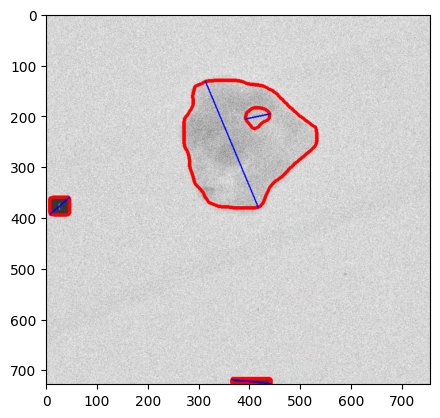

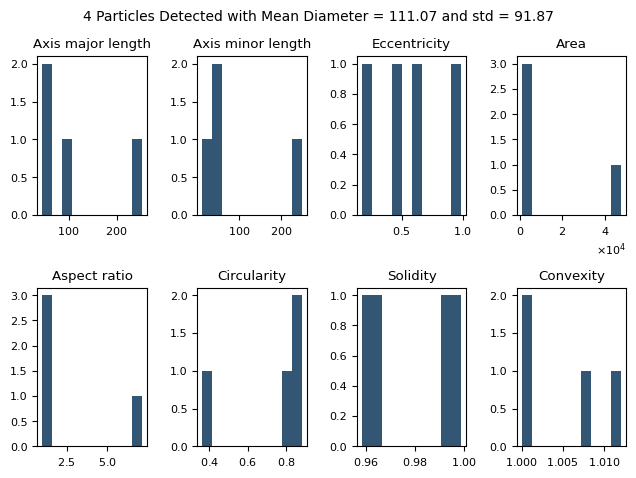

IndexError: list index out of range

In [7]:
img_path = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMapp\\test_libertem.png"

show_instances = True # Show instances in final result

show_diameter = True # Show the major axis in a red line

image, nm_to_px = Utils().read_image(img_path) # Read image, including .dm files

M = image.shape[0]//2
N = image.shape[1]//2

tiles = [image[x:x+M,y:y+N] for x in range(0,image.shape[0],M) for y in range(0,image.shape[1],N)]
tiles = [image]
processed_tiles = []

for image in tiles:
    # Get predictions from model    
    outputs = predictor(image)  # format is documented at https://detectron2.readthedocs.io/tutorials/models.html#model-output-format

    predictions = outputs["instances"].to("cpu")

    boxes = predictions.pred_boxes if predictions.has("pred_boxes") else None

    masks = predictions.pred_masks if predictions.has("pred_masks") else None

    if len(boxes) == 0: # If no detections is found in image

        img = image.copy()

        print("No detections found!")

    else:
    
        diameters=[]

        # Register dataset in COCO format to map class name to class index
        try:
            # If my_dataset_metadata exists
            dataset_dicts = DatasetCatalog.get('my_dataset_metadata')

            nuts_metadata = MetadataCatalog.get('my_dataset_metadata')

        except:

            nuts_metadata = None

            print('No metadata loaded. Classes will be diplayed as numbers.')

        # v = Visualizer(image[:, :, ::-1],
        #                 metadata=nuts_metadata,
        #                 scale=1,
        #                 instance_mode=ColorMode.IMAGE_BW)
        
        # out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
                    
        # img = out.get_image()[:, :, ::-1]

        # Empty list to add particle's properties
        all_masks = []
        all_masks_convex_hull = []

        #For each detection found on image
        for i in range(len(boxes)):
            
            # Get mask detection
            mask = np.asarray(masks[i])
            # Find mask contour using skimage find_contours
            contours, _  = Utils().get_mask_contours(mask)
        
            # Make sure the contours list is not empty          
            if contours != []:
                # If more than one contour found in mask, get the longest
                list_len = [len(i) for i in contours]
                longest_index = np.argmax(np.array(list_len))
                # Sometimes two polygons are found in the same detection, we want to take the last - which is the biggest
                paired_list = list(zip(contours[longest_index][::2], contours[longest_index][1::2]))
                # Convert tuples to lists (optional)
                contours = [list(pair) for pair in paired_list]
                
                # Find diamenter
                point1, point2, diameter = Utils().find_diameter(np.array(contours))

                # Convert to nm
                diameter_nm = round(diameter/nm_to_px , 2)
                # Add to list 
                diameters.append(diameter_nm)

                # Create an empty canvas to plot the contours. This will assure that the calculations are doing done 
                # with the same polygon drawn
                mask = np.zeros_like(image) 
                
                all_masks, all_masks_convex_hull = Utils().get_particle_properties(mask, contours, all_masks, all_masks_convex_hull, nm_to_px)

                points = np.array(contours)

                x = points[:, 0]  # Extract x-coordinates
                y = points[:, 1]  # Extract y-coordinates
                draw_polygon = np.column_stack((x, y)).astype(np.int32)   
                # Draw the contour
                img = cv2.polylines(image, [draw_polygon], isClosed=True, color=(255, 0, 0), thickness=5)

                # Plot diameter on top of segmentation results
                if show_instances:
                    
                    image = img.copy()
                
                if show_diameter:
                    # Plot diameter
                    img = cv2.line(image, (int(point1[0]), int(point1[1])), (int(point2[0]), int(point2[1])), (0, 0, 255), 2) 

        if (show_instances == False and show_diameter == False):
                    
            img = image.copy()

    # PLOT PRED

    processed_tiles.append(img)

    plt.imshow(img, cmap='gray')

    plt.show()

    # PLOT STATS

    final_df = Utils().get_particle_properties_final_df(all_masks, all_masks_convex_hull)

    # Drop entries where major or minor axis are 0 
    # final_df = final_df[final_df.axis_major_length != 0]
    # final_df = final_df[final_df.axis_minor_length != 0]


    figure2 = plt.figure()
    plt.rc('font', size=8)

    #create histogram for each column in DataFrame
    for i, feature in enumerate(final_df.columns[final_df.columns != 'contours']):

        axes2=figure2.add_subplot(2, 4, i+1)
        axes2.ticklabel_format(style='sci', axis='x', scilimits=(-3,3), useMathText=True)  
        final_df.to_csv('./single_image.csv')
        final_df[feature].hist(ax=axes2, grid=False, color='#335674')
        axes2.set_title(str(feature).replace('_', ' ').capitalize(), color='black')
            
    mu = np.round(np.array(diameters).mean(), 2)
    number_of_detections = len(diameters)
    sigma = np.round(np.array(diameters).std(), 2)

    #final_df.to_csv('./single_image.csv')
    figure2.suptitle(str(number_of_detections) + ' Particles Detected with Mean Diameter = ' + str(mu) + ' and std = ' + str(sigma), fontsize=10)
    figure2.tight_layout()

    plt.show()

# Stitch the tiles back together
top_row = np.hstack((processed_tiles[0], processed_tiles[1]))
bottom_row = np.hstack((processed_tiles[2], processed_tiles[3]))
combined_image = np.vstack((top_row, bottom_row))

plt.imshow(np.array(combined_image), cmap='gray')
plt.show()   

In [ ]:
final_df.tail(10)

,contours,axis_major_length,axis_minor_length,eccentricity,area,aspect ratio,circularity,solidity,convexity
182,"[[526.5, 490.5], [525.5, 491.5], [524.5, 491.5...",38.127656,11.448737,0.953853,335.969388,3.330294,0.593265,0.031227,0.179015
183,"[[1239.5, 1406.5], [1238.5, 1407.5], [1237.5, ...",37.926949,9.615034,0.967332,277.136480,3.944546,0.487564,0.029896,0.180997
184,"[[115.5, 1363.5], [114.5, 1364.5], [113.5, 136...",30.127427,10.887378,0.932420,244.961735,2.767189,0.598478,0.029499,0.178832
185,"[[1414.5, 229.5], [1413.5, 230.5], [1412.5, 23...",34.625402,9.600050,0.960797,254.304847,3.606794,0.561771,0.031100,0.178571
186,"[[126.5, 724.5], [125.5, 725.5], [124.5, 725.5...",33.760924,9.544735,0.959204,245.440051,3.537125,0.533363,0.030320,0.178571
187,"[[359.5, 855.5], [358.5, 856.5], [357.5, 857.5...",26.718657,11.392393,0.904543,235.682398,2.345307,0.697780,0.031126,0.178571
188,"[[523.5, 1090.5], [522.5, 1091.5], [521.5, 109...",36.635439,9.395721,0.966553,262.850765,3.899162,0.504548,0.030321,0.178571
189,"[[1848.5, 308.5], [1847.5, 309.5], [1846.5, 30...",34.869425,11.451609,0.944534,304.942602,3.044937,0.589232,0.030510,0.179269
190,"[[1229.5, 815.5], [1228.5, 816.5], [1227.5, 81...",29.093409,9.145309,0.949309,205.835459,3.181239,0.598436,0.031187,0.179260
191,"[[236.5, 20.5], [235.5, 21.5], [234.5, 21.5], ...",33.038272,10.200299,0.951146,258.928571,3.238951,0.573056,0.030898,0.179069


#### Show image and statistics on the detected particles properties

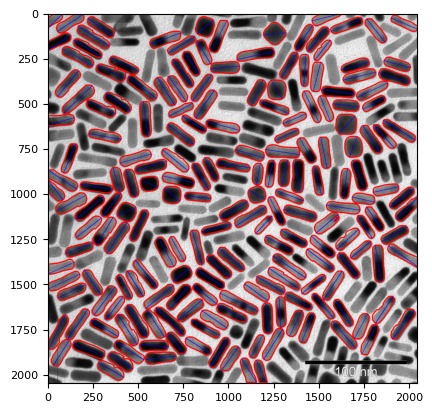

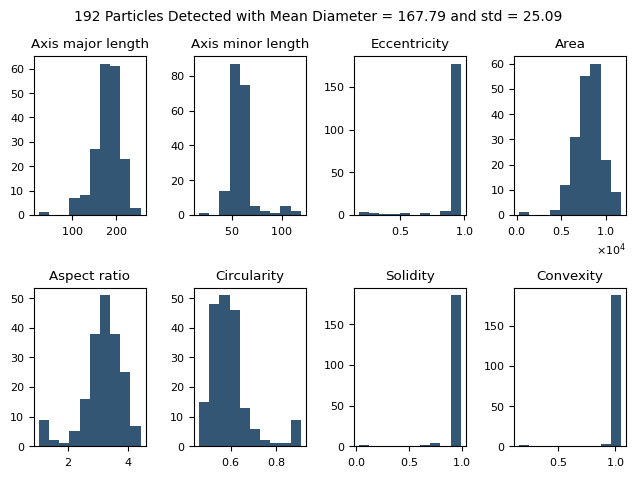

In [ ]:
# PLOT PRED

plt.imshow(img, cmap='gray')

plt.show()

# PLOT STATS

final_df = Utils().get_particle_properties_final_df(all_masks, all_masks_convex_hull)

figure2 = plt.figure()
plt.rc('font', size=8)

#create histogram for each column in DataFrame
for i, feature in enumerate(final_df.columns[final_df.columns != 'contours']):
    
    axes2=figure2.add_subplot(2, 4, i+1)
    axes2.ticklabel_format(style='sci', axis='x', scilimits=(-3,3), useMathText=True)  
    final_df[feature].hist(ax=axes2, grid=False, color='#335674')
    axes2.set_title(str(feature).replace('_', ' ').capitalize(), color='black')
        
mu = np.round(np.array(diameters).mean(), 2)
number_of_detections = len(diameters)
sigma = np.round(np.array(diameters).std(), 2)

figure2.suptitle(str(number_of_detections) + ' Particles Detected with Mean Diameter = ' + str(mu) + ' and std = ' + str(sigma), fontsize=10)
figure2.tight_layout()

plt.show()

#### Predict a directory

In [ ]:
dir_to_segment = 'C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\mini_sample\\'

show_instances = True

show_diameter = False

#### Register dataset in COCO format

In [ ]:
# Register dataset in COCO format
try:

    dataset_dicts = DatasetCatalog.get("my_dataset_metadata")
    nuts_metadata = MetadataCatalog.get("my_dataset_metadata")

except:

    nuts_metadata = None
    print("No metadata found. Classes will be shown as numbers.")


Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.



#### Initiate pandas dataframe to store results and create directory to save them

In [ ]:

dir_df = pd.DataFrame()

df_mean_results_final = pd.DataFrame()

dir_to_save = './segmentations/' + datetime.datetime.now().strftime("%Y%m%d%H%M%S") + '/'

try: 
    os.mkdir(dir_to_segment + '/segmentations/')

except: pass

os.mkdir(dir_to_segment + dir_to_save)

#### Loop over all images in directory

In [ ]:
for image_name in os.listdir(dir_to_segment):

    if image_name.endswith(('.jpg', '.png', '.jpeg', '.tiff', '.dm3', '.dm4')):

        image, nm_to_px = Utils().read_image(dir_to_segment + '/' + image_name)

        # Get predictions from model    
        outputs = predictor(image)  # format is documented at https://detectron2.readthedocs.io/tutorials/models.html#model-output-format
        
        predictions = outputs["instances"].to("cpu")
        
        boxes = predictions.pred_boxes if predictions.has("pred_boxes") else None
       
        masks = predictions.pred_masks if predictions.has("pred_masks") else None

        if len(boxes) == 0: # If no detections found, save the image with no detection and add it's name to dataframe

            img = image.copy()

            cv2.imwrite(dir_to_segment  + dir_to_save + image_name + '.png', img) # save image      

            final_df = pd.DataFrame()
            
            final_df['FileName'] = [image_name]

            dir_df = pd.concat([dir_df, final_df]) 

            df_mean_results_final = pd.concat([df_mean_results_final, final_df]) 

        else:
 
            diameters=[]

            # Plot contour using COCO Visualisation method
            if show_instances:
                
                v = Visualizer(image[:, :, ::-1],
                    metadata=nuts_metadata,
                    scale=1,
                    instance_mode=ColorMode.IMAGE_BW)
                
                out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
                
                img = out.get_image()[:, :, ::-1]

            # Empty list to add particle's properties
            all_masks = []
            all_masks_convex_hull = []

            for i in range(len(boxes)):
                        
                # Get mask detection
                mask = np.asarray(masks[i])
                # Find mask contour using skimage find_contours
                contours = Utils().get_mask_contours(mask)
                # Make sure the contours list is not empty              
                if contours != []:
                    # Find diamenter
                    point1, point2, diameter = Utils().find_diameter(np.array(contours[0]))
                    # Convert to nm
                    diameter_nm = round(diameter/nm_to_px , 2)
                    # Add to list 
                    diameters.append(diameter_nm)

                    all_masks, all_masks_convex_hull = Utils().get_particle_properties(mask, contours[0], all_masks, all_masks_convex_hull, nm_to_px)

                    # Plot diameter on top of segmentation results
                    if show_instances:
                        
                        image = img.copy()
                    
                    if show_diameter:
                        # Plot diameter
                        img = cv2.line(image, tuple(point1), tuple(point2), (0, 0, 255), 2) 

            if (show_instances == False and show_diameter == False):
                        
                img = image.copy()

            cv2.imwrite(dir_to_segment  + dir_to_save + os.path.splitext(image_name)[0] + '.png', img) # save image

            final_df = Utils().get_particle_properties_final_df(all_masks, all_masks_convex_hull)
            
            final_df['FileName'] = image_name
            
            dir_df = pd.concat([dir_df, final_df])              

            df_mean_results_image = pd.DataFrame() # Create mean results for all detections in one image

            # Get mean value of all columns except filename
            for col in dir_df.loc[:, dir_df.columns != 'FileName'].columns:

                if col == 'contours':

                    df_mean_results_image[f'{col}_all'] = dir_df[col].values.tolist()

                else:

                    df_mean_results_image[f'{col}_mean'] = [dir_df[col].mean()]

                    df_mean_results_image[f'{col}_std'] = [dir_df[col].std()]

            df_mean_results_image['FileName'] = image_name

            df_mean_results_image['Number of Detections'] = len(boxes)

            # If the file is .dm, get metadata info to add to csv
            if image_name.endswith(('.dm3', '.dm4')):
                
                dm4_info = Utils().get_dm4_info(dir_to_segment + '/' + image_name)

                dm4_info = pd.DataFrame(dm4_info)

                df_mean_results_image_dm4 = pd.concat([df_mean_results_image, dm4_info], axis=1) 

            else:

                df_mean_results_image_dm4 = df_mean_results_image.copy()

            df_mean_results_final = pd.concat([df_mean_results_final, df_mean_results_image_dm4]) 

# Save both dataframes

dir_df.to_csv('./stats.csv')

df_mean_results_final.to_csv('./mean_stats.csv')


c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\functional.py:539: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:3638.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


df_mean_results_image                                          contours_all
0  [[[1981, 1581], [1980, 1581], [1979, 1581], [1...


The csv files can be used to create a [Datasette](https://datasette.io/) tool, more on this on the datasette.ipynb

#### Visualise statistics for the nanoparticles detected in directory

45 particles detected in 11 files.
Results saved in ./segmentations/20240807141827/


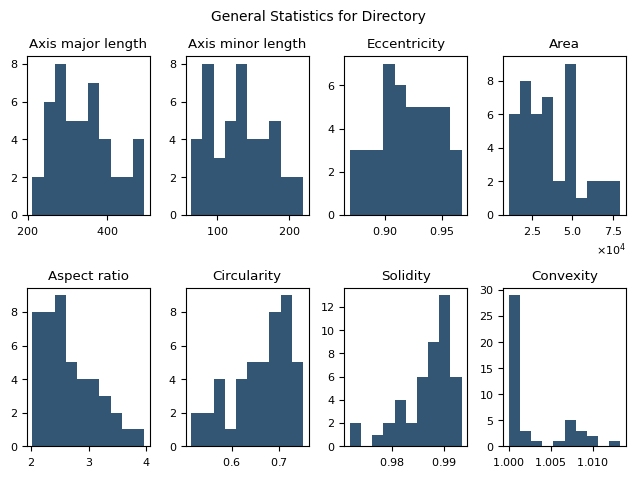

In [ ]:
figure = plt.figure()
plt.rc('font', size=8)

if dir_df.empty:

    print("No image found on directory.")

elif len(dir_df.columns) == 1:

    print("No particles detected on images.")

else:

    #create histogram for each column in DataFrame
    for i, feature in enumerate(dir_df.loc[:, dir_df.columns != 'FileName'].columns):
        
        axes2=figure.add_subplot(2, 4, i+1)
        axes2.ticklabel_format(style='sci', axis='x', scilimits=(-3,3), useMathText=True)  
        dir_df[feature].hist(ax=axes2, grid=False, color='#335674')
        axes2.set_title(str(feature).replace('_', ' ').capitalize(), color='black')

    figure.suptitle('General Statistics for Directory', fontsize=10)
    figure.tight_layout()

print((str(len(dir_df.index)) + " particles detected in " + str(dir_df['FileName'].nunique()) + " files.\nResults saved in " + dir_to_save))

## Load raw image and csv annotations

In [7]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ast
import sys
import numpy as np
sys.path.append("../")

from utils import Utils

dir_path = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\"



In [8]:
annotations = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\mini_sample\\segmentations\\20250409100721\\stats.csv", index_col=0)

#contours is being read as string. ast.literal_eval can only be done once
try:
    annotations["contours"] = annotations["contours"].apply(ast.literal_eval)     

except: pass    

annotations

,contours,axis_major_length,axis_minor_length,eccentricity,area,aspect ratio,circularity,solidity,convexity,FileName,OriginalPath,nm2pixels,PredictionModel
0,"[[2013.5, 1524.5], [2012.5, 1525.5], [2011.5, ...",27.252798,13.258105,0.873688,278.348657,2.055558,0.736115,0.092629,0.310897,L1-2-A.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,3.225,NaN
1,"[[1983.5, 965.5], [1982.5, 966.5], [1981.5, 96...",26.908803,13.874387,0.856825,290.271017,1.939459,0.761955,0.093817,0.310078,L1-2-A.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,3.225,NaN
2,"[[2050.5, 538.5], [2049.5, 539.5], [2048.5, 53...",25.598623,16.432591,0.766761,329.499429,1.557796,0.850389,0.094440,0.312518,L1-2-A.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,3.225,NaN
3,"[[401.5, 777.5], [400.5, 778.5], [399.5, 778.5...",25.366484,14.254145,0.827186,282.771468,1.779586,0.807267,0.094100,0.311785,L1-2-A.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,3.225,NaN
4,"[[1504.5, 547.5], [1503.5, 548.5], [1502.5, 54...",21.527333,10.944510,0.861121,183.354366,1.966953,0.786528,0.093739,0.310078,L1-2-A.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,3.225,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,"[[359.5, 855.5], [358.5, 856.5], [357.5, 857.5...",26.718657,11.392393,0.904543,235.682398,2.345307,0.697780,0.031126,0.178571,rod_opt_solution_1_C.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,5.600,NaN
188,"[[523.5, 1090.5], [522.5, 1091.5], [521.5, 109...",36.635439,9.395721,0.966553,262.850765,3.899162,0.504548,0.030321,0.178571,rod_opt_solution_1_C.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,5.600,NaN
189,"[[1848.5, 308.5], [1847.5, 309.5], [1846.5, 30...",34.869425,11.451609,0.944534,304.942602,3.044937,0.589232,0.030510,0.179269,rod_opt_solution_1_C.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,5.600,NaN
190,"[[1229.5, 815.5], [1228.5, 816.5], [1227.5, 81...",29.093409,9.145309,0.949309,205.835459,3.181239,0.598436,0.031187,0.179260,rod_opt_solution_1_C.png,C:/Users/Natalia/OneDrive/Documents/TEMData/Gl...,5.600,NaN


In [ ]:
extensions = ["*.png"]
        
# Find all image files in directory
image_files = []
for ext in extensions:
    image_files.extend(sorted(
        [os.path.join(dir_path, f) for f in os.listdir(dir_path) if f.lower().endswith(ext[1:])],
        key=str.lower
    ))

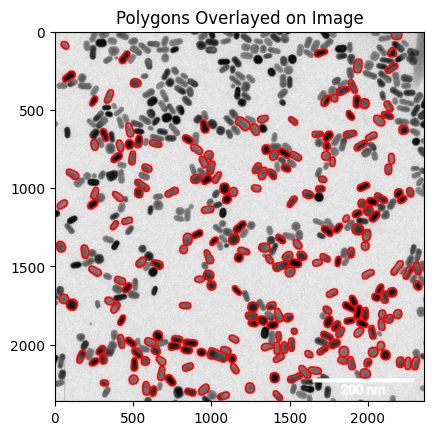

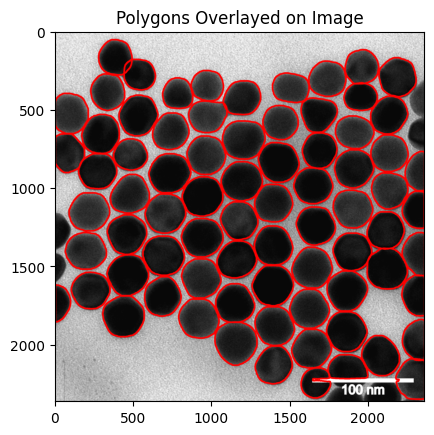

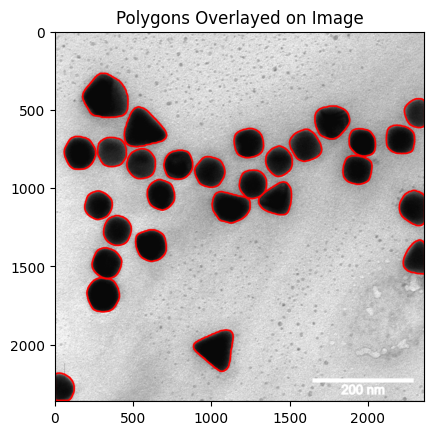

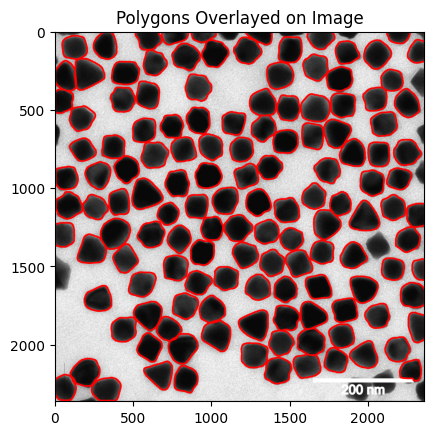

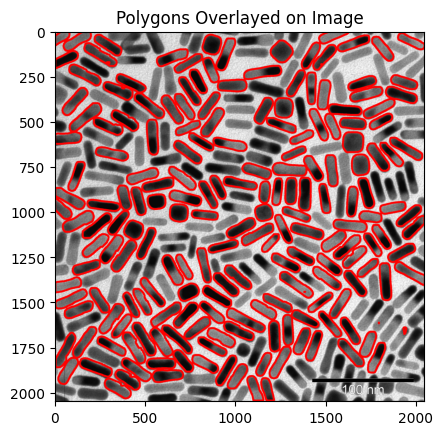

In [ ]:
import cv2

for img_path in image_files:

    dir_path, img_name = os.path.split(img_path)

    if annotations is not None:
        # Check if annotation is available for image
        if img_name in annotations.FileName.values.tolist():

            image, nm_to_px = Utils().read_image(img_path) # Read image, including .dm files

            #Get contour value for this filename
            contours = annotations.loc[annotations["FileName"] == img_name, "contours"]
            #print(contours)
            # Plot each polygon
            annotated_image = np.copy(image)  

            #segmented_image = raw_image.copy()  # Initialize with a fresh copy

            for polygon in contours:

                if polygon != []:
                    # Convert polygon coordinates to a NumPy array
                    points = np.array(polygon)

                    x = points[:, 0]  # Extract x-coordinates
                    y = points[:, 1]  # Extract y-coordinates
                    draw_polygon = np.column_stack((x, y)).astype(np.int32)   

                    
                    # Draw the bumpy circle contour
                    cv2.polylines(annotated_image, [draw_polygon], isClosed=True, color=(255, 0, 0), thickness=10)

            plt.title("Polygons Overlayed on Image")
            #plt.show()
            # print(contour[0])
            plt.imshow(annotated_image, cmap='gray')
            plt.show()

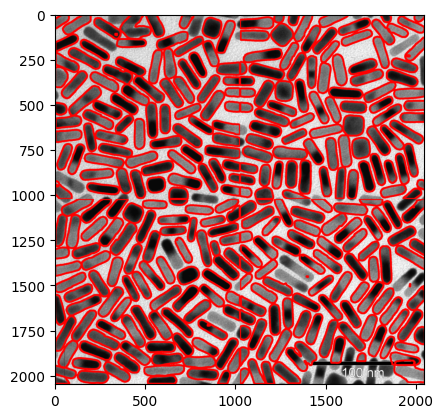

In [ ]:
img_path = 'C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\mini_sample\\rod_opt_solution_1_C.png'

dir_path, img_name = os.path.split(img_path)

image, nm_to_px = Utils().read_image(img_path)

M = image.shape[0]//2
N = image.shape[1]//2

tiles = [image[x:x+M,y:y+N] for x in range(0,image.shape[0],M) for y in range(0,image.shape[1],N)]

processed_tiles = []
all_contours = []

for tile in tiles:
    # Get predictions from model    
    outputs = predictor(tile)  # format is documented at https://detectron2.readthedocs.io/tutorials/models.html#model-output-format

    predictions = outputs["instances"].to("cpu")

    boxes = predictions.pred_boxes if predictions.has("pred_boxes") else None

    masks = predictions.pred_masks if predictions.has("pred_masks") else None

    if len(boxes) == 0: # If no detections found, save the image with no detection and add it's name to dataframe

        tile = tile.copy()

    else:

        for i in range(len(boxes)):
                
            # Get mask detection
            mask = np.asarray(masks[i])
            # Find mask contour using skimage find_contours
            contours, _ = Utils().get_mask_contours(mask)

            #print('1: ', contours)

            paired_list = list(zip(contours[0][::2], contours[0][1::2]))
            # Convert tuples to lists (optional)
            contours = [list(pair) for pair in paired_list]

            all_contours.append(contours)

            # Make sure the contours list is not empty              
            if contours != []:

                # Convert polygon coordinates to a NumPy array

                #print('2: ', contours)
                points = np.array(contours)

                x = points[:, 0]  # Extract x-coordinates
                y = points[:, 1]  # Extract y-coordinates
                draw_polygon = np.column_stack((x, y)).astype(np.int32)   

                
                # Draw the bumpy circle contour
                processed_tile = cv2.polylines(tile, [draw_polygon], isClosed=True, color=(255, 0, 0), thickness=10)
    
    processed_tiles.append(processed_tile)

# Stitch the tiles back together
top_row = np.hstack((processed_tiles[0], processed_tiles[1]))
bottom_row = np.hstack((processed_tiles[2], processed_tiles[3]))
combined_image = np.vstack((top_row, bottom_row))

plt.imshow(combined_image, cmap='gray')
plt.show()


### Segmenting with Sliding Window

In [1]:
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog, DatasetCatalog
import matplotlib.pyplot as plt
import datetime
import os
import pandas as pd
import numpy as np
import cv2

import sys
sys.path.append("../")

from utils import Utils

c:\Users\Natalia\anaconda3\envs\pyqt6\lib\site-packages\torch\utils\_pytree.py:185: FutureWarning: optree is installed but the version is too old to support PyTorch Dynamo in C++ pytree. C++ pytree support is disabled. Please consider upgrading optree using `python3 -m pip install --upgrade 'optree>=0.13.0'`.
  warnings.warn(
INFO:albumentations.check_version:A new version of Albumentations is available: 2.0.5 (you have 1.4.13). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.


In [2]:
model_path = '../models/model_final_mary-scott2.pth'
num_of_classes = 1
iou_thresh = 0.8

In [3]:
cfg = get_cfg()
cfg.merge_from_file("../detectron2Files/mask_rcnn_X_101_32x8d_FPN_3x.yaml")

cfg.MODEL.DEVICE = 'cpu'
cfg.DATALOADER.NUM_WORKERS = 2
cfg.SOLVER.IMS_PER_BATCH = 1  # This is the real "batch size" commonly known to deep learning people
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 1024   # The "RoIHead batch size". 128 is faster, and good enough for this toy dataset (default: 512)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = num_of_classes
cfg.MODEL.WEIGHTS = model_path  # path to the model we just trained
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = iou_thresh   # set a custom testing threshold
cfg.TEST.DETECTIONS_PER_IMAGE = 5000

In [5]:
predictor = DefaultPredictor(cfg)

INFO:detectron2.checkpoint.detection_checkpoint:[DetectionCheckpointer] Loading from ../models/model_final_mary-scott2.pth ...
INFO:fvcore.common.checkpoint:[Checkpointer] Loading from ../models/model_final_mary-scott2.pth ...


In [11]:
def sliding_window(image, window_size, stride):
    # Get image dimensions
    h, w = image.shape[:2]
    win_h, win_w = window_size

    # Calculate the number of windows in each dimension
    n_h = (h - win_h) // stride + 1
    n_w = (w - win_w) // stride + 1

    # Generate windows
    windows = []
    for i in range(n_h):
        for j in range(n_w):
            y_start = i * stride
            y_end = y_start + win_h
            x_start = j * stride
            x_end = x_start + win_w
            window = image[y_start:y_end, x_start:x_end]
            windows.append(((y_start, y_end, x_start, x_end), window))
    return windows

# def reconstruct_image(windows, original_shape, window_size, stride):
#     h, w = original_shape[:2]
#     win_h, win_w = window_size

#     # Initialize output and weight matrices
#     output = np.zeros(original_shape, dtype=np.float32)
#     weights = np.zeros(original_shape, dtype=np.float32)

#     # Accumulate window contributions
#     for (y_start, y_end, x_start, x_end), window in windows:
#         output[y_start:y_end, x_start:x_end] += window
#         weights[y_start:y_end, x_start:x_end] += 1

#     # Normalize by the number of contributions (avoid division by zero)
#     output = np.divide(output, weights, where=weights != 0)
#     return output.astype(np.uint8)

def reconstruct_image(windows, original_shape, window_size, stride):
    
    #preserve processed image content while keeping annotations at full intensity

    h, w = original_shape[:2]
    image_accumulator = np.zeros(original_shape, dtype=np.float32)
    weight_accumulator = np.zeros(original_shape, dtype=np.float32)
    annotation_layer = np.zeros(original_shape, dtype=np.uint8)

    for (y_start, y_end, x_start, x_end), window in windows:
        # Separate processing results from annotations
        processed_window = window.copy()
        red_annotations = (window[..., 0] == 255) & (window[..., 1] == 0) & (window[..., 2] == 0)
        
        # Accumulate processed content
        image_accumulator[y_start:y_end, x_start:x_end] += processed_window
        weight_accumulator[y_start:y_end, x_start:x_end] += 1
        
        # Keep annotations at full intensity
        annotation_layer[y_start:y_end, x_start:x_end] = np.where(
            red_annotations[..., None], 
            [255, 0, 0], 
            annotation_layer[y_start:y_end, x_start:x_end]
        )

    # Reconstruct processed image
    processed_image = np.divide(image_accumulator, weight_accumulator, where=weight_accumulator!=0)
    processed_image = processed_image.astype(np.uint8)
    
    # Overlay annotations
    final_image = np.where(annotation_layer.any(axis=-1, keepdims=True), 
                          annotation_layer, 
                          processed_image)
    
    return final_image

def is_overlapping_border(polygon, y_start, y_end, x_start, x_end):
    """Check if any vertex of the polygon is outside the array boundaries."""
    for x, y in polygon:
        if x-5 <= x_start or x+5 <= x_start or x+5 >= x_end or x-5 >= x_end or y-5 <= y_start or y+5 <= y_start or y+5 >= y_end or y-5 >= y_end:

            return True  # Polygon overlaps with the border
        
    return False  # Polygon is inside the bounds

def is_duplicate(contour, existing_contours, area_threshold=5, match_threshold=0.1):
    """
    Checks if a contour is similar to existing ones using area and shape matching.
    """
    # Compute area and perimeter of the new contour
    area = cv2.contourArea(contour)
    
    for existing in existing_contours:
        # Quick check: Compare areas
        existing_area = cv2.contourArea(existing)
        if abs(area - existing_area) > area_threshold:
            continue
        
        # Shape matching (lower value = more similar)
        match = cv2.matchShapes(contour, existing, cv2.CONTOURS_MATCH_I2, 0)
        if match < match_threshold:
            return True
    return False

def compute_iou(bbox1, bbox2):
    """
    Compute IoU, robust to division-by-zero.
    Returns 0.0 if union area is zero.
    """
    # Get intersection coordinates
    x_left = max(bbox1[0], bbox2[0])
    y_top = max(bbox1[1], bbox2[1])
    x_right = min(bbox1[2], bbox2[2])
    y_bottom = min(bbox1[3], bbox2[3])

    # Check if there is no overlap
    if x_right < x_left or y_bottom < y_top:
        return 0.0

    # Calculate intersection area
    intersection_area = (x_right - x_left) * (y_bottom - y_top)

    # Calculate union area
    area1 = (bbox1[2] - bbox1[0]) * (bbox1[3] - bbox1[1])
    area2 = (bbox2[2] - bbox2[0]) * (bbox2[3] - bbox2[1])
    union_area = area1 + area2 - intersection_area

    # Avoid division by zero
    if union_area == 0:
        return 0.0
    return intersection_area / union_area

In [12]:
import h5py

In [ ]:
#img_path = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\2021-02-04_silicaSpheres_200nm_A5\\13kX _OneView _300kV _0028.dm4"

dir_path = "C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-png\\"

#list4tile = ['30 nm_0000.png', '30 nm_0002.png', '30 nm_0003.png', '30 nm_0007.png', '30 nm_0016.png', '30 nm_0018.png']
for i in os.listdir(dir_path):
#for i in list4tile:

    img_path = dir_path + '/' + i

    dir_path, img_name = os.path.split(img_path)

    if img_name.endswith(('.jpg', '.png', '.jpeg', '.tiff', '.dm3', '.dm4')):

        try:

            image, nm_to_px = Utils().read_image(img_path)

        except:

            image = np.zeros((100,100,3))

        # window_size = (image.shape[0], image.shape[1])  # Height, Width
        # print('window_size ', window_size)
        # stride = window_size[0]  # Overlap = window_size - stride
        # print('stride', stride)

        window_size = (image.shape[0]//2, image.shape[1]//2)  # Height, Width
        print('window_size ', window_size)
        stride = window_size[0]//2  # Overlap = window_size - stride
        print('stride', stride)

        # Generate sliding windows
        windows = sliding_window(image, window_size, stride)

        # Process each window (replace with your processing)
        processed_windows = []
        all_contours = []
        existing_bboxes = []


        for (coords, window) in windows:

        
            # Get predictions from model    
            outputs = predictor(window)  # format is documented at https://detectron2.readthedocs.io/tutorials/models.html#model-output-format

            predictions = outputs["instances"].to("cpu")

            # boxes = predictions.pred_boxes if predictions.has("pred_boxes") else None

            # masks = predictions.pred_masks if predictions.has("pred_masks") else None

            processed_window = window.copy()

            if len(predictions) > 0: # If no detections found, save the image with no detection
                
                for i in range(len(predictions)):
                        
                    # Get mask detection
                    mask = predictions.pred_masks[i]

                    # Find mask contour using skimage find_contours
                    contours, _ = Utils().get_mask_contours(mask)

                    if contours != []:
                        # If more than one contour found in mask, get the longest
                        list_len = [len(i) for i in contours]
                        longest_index = np.argmax(np.array(list_len))
                        # Sometimes two polygons are found in the same detection, we want to take the last - which is the biggest
                        paired_contours = list(zip(contours[longest_index][::2], contours[longest_index][1::2]))
                        

                        # The contours will have the coordinates for the window. We want to translate for the full image
                        translated_contours = [(x + coords[2], y + coords[0]) for x, y in zip(contours[longest_index][::2], contours[longest_index][1::2])]

                        # Calculate bounding box
                        min_x = min(p[0] for p in translated_contours)
                        min_y = min(p[1] for p in translated_contours)
                        max_x = max(p[0] for p in translated_contours)
                        max_y = max(p[1] for p in translated_contours)
                        new_bbox = (min_x, min_y, max_x, max_y)

                        # Check for duplicates using IoU
                        is_duplicate = False
                        for existing_bbox in existing_bboxes:

                            if compute_iou(new_bbox, existing_bbox) > 0.9:
                                is_duplicate = True
                                break

                        # Extract window boundary
                        y_start, y_end, x_start, x_end = coords[0], coords[1], coords[2], coords[3]

                        # Extract masked pixels from original image
                        masked_pixels = window[mask]
                        # Remove region containing white pixels - its the ruler
                        is_white = np.any(np.all(masked_pixels == 255, axis=1))
                        # Remove region containing black pixels - its the ruler
                        is_black = np.any(np.all(masked_pixels == 0, axis=1))
                
                        # Remove detections in the boundaries do we don't have "half particles"
                        if not is_overlapping_border(translated_contours, y_start, y_end, x_start, x_end) and not (is_white or is_black):
                        
                        # Filter contours that do not touch the border
                        #if not is_overlapping_border(translated_contours, y_start, y_end, x_start, x_end):

                            if not is_duplicate:
                
                                
                                #existing_bboxes.append(new_bbox)

                                # Make sure the contours list is not empty              
                                if paired_contours != []:

                                    all_contours.append(translated_contours)
                                    existing_bboxes.append(new_bbox)

                                    # Convert polygon coordinates to a NumPy array

                                    #print('2: ', contours)
                                    points = np.array(paired_contours)

                                    x = points[:, 0]  # Extract x-coordinates
                                    y = points[:, 1]  # Extract y-coordinates
                                    draw_polygon = np.column_stack((x, y)).astype(np.int32)   

                                    
                                    # Draw the bumpy circle contour
                                    processed_window = cv2.polylines(processed_window, [draw_polygon], isClosed=True, color=(255, 0, 0), thickness=5)
                    
            processed_windows.append((coords, processed_window))

        # Stitch the tiles back together
        reconstructed = reconstruct_image(processed_windows, image.shape, window_size, stride)

        #cv2.imwrite("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\GMangan\Segmentations\\" + img_name + ".png", reconstructed)
        cv2.imwrite("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\mary-scott-png\\Segmentations\\2\\tile_" + img_name + ".png", reconstructed)
        print(reconstructed.shape)

    # plt.imshow(reconstructed, cmap='gray')
    # plt.show()

0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
window_size  (1024, 1024)
stride 512
(4096, 4096, 3)
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
window_size  (1024, 1024)
stride 512
(4096, 4096, 3)
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
window_size  (1024, 1024)
stride 512
(4096, 4096, 3)
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
window_size  (1024, 1024)
stride 512
(4096, 4096, 3)
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
window_size  (1024, 1024)
stride 512
(4096, 4096, 3)
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
window_size  (1024, 1024)
stride 512
(4096, 4096, 3)
0
255
Invalid format: _

Couldn't get ruler size, setting 1 pixel = 1 nm
window_size  (1024, 1024)
stride 512


KeyboardInterrupt: 

In [7]:
len(all_contours)

4

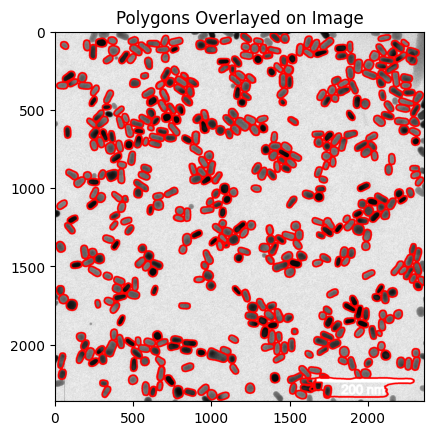

In [ ]:
img_path = 'C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\L1-2-A.png'

if all_contours is not None:

        image, nm_to_px = Utils().read_image(img_path) # Read image, including .dm files

        #Get contour value for this filename
        
        #print(contours)
        # Plot each polygon
        annotated_image = np.copy(image)  

        #segmented_image = raw_image.copy()  # Initialize with a fresh copy

        for polygon in all_contours:

            if polygon != []:
                # Convert polygon coordinates to a NumPy array
                points = np.array(polygon)

                x = points[:, 0]  # Extract x-coordinates
                y = points[:, 1]  # Extract y-coordinates
                draw_polygon = np.column_stack((x, y)).astype(np.int32)   

                
                # Draw the bumpy circle contour
                cv2.polylines(annotated_image, [draw_polygon], isClosed=True, color=(255, 0, 0), thickness=5)

        plt.title("Polygons Overlayed on Image")
        #plt.show()
        # print(contour[0])
        plt.imshow(annotated_image, cmap='gray')
        plt.imsave('./L1-2-A.png', annotated_image)
        plt.show()

#### Replace new results in CSV

In [ ]:
old_annotations = pd.read_csv("C:\\Users\\Natalia\\OneDrive\\Documents\\TEMData\\Glasgow_png\\mini_sample\\segmentations\\20250402000811\\stats.csv", index_col=0)

#contours is being read as string. ast.literal_eval can only be done once
try:
    old_annotations["contours"] = old_annotations["contours"].apply(ast.literal_eval)     

except: pass    

old_annotations

,contours,axis_major_length,axis_minor_length,eccentricity,area,aspect ratio,circularity,solidity,convexity,FileName
0,"[[2013.5, 1524.5], [2012.5, 1525.5], [2011.5, ...",87.890274,42.757390,0.873688,2895.0,2.055558,0.736115,0.963394,1.002642,L1-2-A.png
1,"[[1983.5, 965.5], [1982.5, 966.5], [1981.5, 96...",86.780891,44.744898,0.856825,3019.0,1.939459,0.761955,0.975760,1.000000,L1-2-A.png
2,"[[2050.5, 538.5], [2049.5, 539.5], [2048.5, 53...",82.555558,52.995106,0.766761,3427.0,1.557796,0.850389,0.982230,1.007871,L1-2-A.png
3,"[[401.5, 777.5], [400.5, 778.5], [399.5, 778.5...",81.806910,45.969617,0.827186,2941.0,1.779586,0.807267,0.978702,1.005506,L1-2-A.png
4,"[[1504.5, 547.5], [1503.5, 548.5], [1502.5, 54...",69.425649,35.296045,0.861121,1907.0,1.966953,0.786528,0.974949,1.000000,L1-2-A.png
...,...,...,...,...,...,...,...,...,...,...
193,"[[359.5, 855.5], [358.5, 856.5], [357.5, 857.5...",149.624482,63.797403,0.904543,7391.0,2.345307,0.697780,NaN,NaN,rod_opt_solution_1_C.png
194,"[[523.5, 1090.5], [522.5, 1091.5], [521.5, 109...",205.158458,52.616036,0.966553,8243.0,3.899162,0.504548,NaN,NaN,rod_opt_solution_1_C.png
195,"[[1848.5, 308.5], [1847.5, 309.5], [1846.5, 30...",195.268780,64.129008,0.944534,9563.0,3.044937,0.589232,NaN,NaN,rod_opt_solution_1_C.png
196,"[[1229.5, 815.5], [1228.5, 816.5], [1227.5, 81...",162.923093,51.213731,0.949309,6455.0,3.181239,0.598436,NaN,NaN,rod_opt_solution_1_C.png


In [ ]:
img_name = 'L1-2-A.png'
replace_annotations = True

if replace_annotations == True:

    #Find image name in csv
    if img_name in old_annotations.FileName.values.tolist():

        print(img_name)
        #image, nm_to_px = Utils().read_image(img_path) # Read image, including .dm files

        #Get contour value for this filename
        try:
            old_annotations = old_annotations[old_annotations.FileName != img_name]
        except Exception as err:          
            print(f"Unexpected {err=}, {type(err)=}")

    diameters = []

    all_masks = []
    
    all_masks_convex_hull = []

    for contour in all_contours:

        point1, point2, diameter = Utils().find_diameter(np.array(contour))
        # Convert to nm
        diameter_nm = round(diameter/nm_to_px , 2)
        # Add to list 
        diameters.append(diameter_nm)

        #Create mask of polygon to get particle properties
        mask_array = np.zeros_like(image)

        # Draw the bumpy circle contour
        #cv2.polylines(mask_array, [draw_polygon], isClosed=True, color=(255, 255, 255), thickness=10)

        # cv2.fillPoly(mask_array, [draw_polygon], color=(255, 255, 255))

        # The append is already inside the function

        all_masks, all_masks_convex_hull = Utils().get_particle_properties(mask_array, contour, all_masks, all_masks_convex_hull, nm_to_px)

    
    final_img_df = Utils().get_particle_properties_final_df(all_masks, all_masks_convex_hull)
                    
    final_img_df['FileName'] = img_name


new_annotations = pd.concat([old_annotations, final_img_df])   

In [ ]:
new_annotations

,contours,axis_major_length,axis_minor_length,eccentricity,area,aspect ratio,circularity,solidity,convexity,FileName
0,"[[1184.5, 318.5], [1183.5, 319.5], [1182.5, 31...",245.858370,215.976643,0.477817,41608.0,1.138356,0.891112,0.992439,1.002299,L2-11-1-D.png
1,"[[1466.5, 268.5], [1465.5, 269.5], [1464.5, 26...",243.977353,190.222534,0.626187,36294.0,1.282589,0.866673,0.990205,1.000808,L2-11-1-D.png
2,"[[946.5, 252.5], [945.5, 253.5], [944.5, 253.5...",209.222522,196.892324,0.338221,32299.0,1.062624,0.892411,0.991771,1.000000,L2-11-1-D.png
3,"[[1716.5, 192.5], [1715.5, 193.5], [1714.5, 19...",241.186897,228.293484,0.322581,43170.0,1.056477,0.893245,0.991183,1.003016,L2-11-1-D.png
4,"[[493.5, 181.5], [492.5, 182.5], [491.5, 182.5...",210.998183,195.177392,0.379920,32280.0,1.081059,0.897579,0.991766,1.001746,L2-11-1-D.png
...,...,...,...,...,...,...,...,...,...,...
567,"[(1939.5, 1752.5), (1938.5, 1753.5), (1937.5, ...",96.165838,44.660044,0.885622,3315.0,2.153286,0.735897,0.970149,1.000000,L1-2-A.png
568,"[(2060.5, 1913.5), (2059.5, 1914.5), (2058.5, ...",40.262265,30.291150,0.658768,953.0,1.329176,0.925711,0.981462,1.000000,L1-2-A.png
569,"[(1706.5, 2202.5), (1705.5, 2203.5), (1704.5, ...",631.529916,139.588416,0.975267,60827.0,4.524229,0.283122,0.837307,1.093128,L1-2-A.png
570,"[(1923.5, 2161.5), (1922.5, 2162.5), (1921.5, ...",64.277077,36.866352,0.819168,1822.0,1.743516,0.769735,0.970181,1.000000,L1-2-A.png
